# Labjournaal BM
## General
**Name:**  
**Title of the experiment:** Bepaling van de constante van Boltzmann  
**Starting date:**  
**Expected enddate:**  
**Partner:**  
**Goal of the experiment:** Het $(I,V)$-karakteristiek van een silicium diode bepalen en daaruit de constante van Boltzmann $k_B$ (of de idealiteitsfactor $n$) bepalen. Daarnaast leren omgaan met DMM's en de spanningsdeler.  
**Research question:** Welke waarde van $k_B$ (met onzekerheid) volgt uit de $(I,V)$-karakteristiek van de diode?  
**Expectations or Hypothesis:**  
**Desired accuracy:**  

In [14]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
%matplotlib widget

# Preparation

**Assignments:**

---
### Opdracht 1 – Nauwkeurigheid en gevoeligheid van een DMM

**a) Nauwkeurigheid.** Specificatie voor het $10\,\mathrm{V}$-bereik: $\pm(0{,}0015\,\%$ van de aflezing $+\ 0{,}0004\,\%$ van het bereik$)$. Aflezing: $5{,}00000\,\mathrm{V}$.

- aflezing: $0{,}0015\,\% \cdot 5{,}00000\,\mathrm{V} = 75\,\mu\mathrm{V}$
- bereik: $0{,}0004\,\% \cdot 10\,\mathrm{V} = 40\,\mu\mathrm{V}$
- totaal: $75 + 40 = 115\,\mu\mathrm{V}$

Resultaat: $U = 5{,}00000 \pm 0{,}00012\,\mathrm{V}$. (De laatste twee getoonde cijfers zijn dus niet betrouwbaar.)

**b) Gevoeligheid.** Een $4\frac{1}{2}$ digit DMM toont $0$ t/m $19999$ (20000 tellen). Op het $200\,\mathrm{mV}$-bereik is één tel dus $200\,\mathrm{mV}/20000 = 0{,}01\,\mathrm{mV} = 10\,\mu\mathrm{V}$. De gevoeligheid is dus $10\,\mu\mathrm{V}$. Bij $9\,\mathrm{mV}$ is dat een relatieve resolutie van ca. $0{,}11\,\%$.

---
### Opdracht 2 – Waarom niet direct meten aan de diode?

**Stroom direct meten is niet handig:**

- De stroom verandert in het meetgebied $0{,}1$–$0{,}6\,\mathrm{V}$ over ca. 5 decades. Je moet dan steeds van bereik wisselen, en de kleinste stromen (grofweg nA) liggen onder de gevoeligheid van een gewone DMM.
- Een stroommeter heeft een inwendige weerstand $R_i$ (shunt, in de laagste bereiken $100\,\Omega$–$1\,\mathrm{k}\Omega$). Bij $U_D \approx 0{,}6\,\mathrm{V}$ is de diodeweerstand maar enkele honderden $\Omega$, dus $R_i$ is vergelijkbaar met $R_D$. De meter verstoort de schakeling: er valt spanning over de meter en de stroom wordt kleiner.

**Spanning direct over de diode meten is niet nauwkeurig:**

- Bij lage spanning is $R_D$ van de orde $\mathrm{M}\Omega$. De spanningsmeter ($R_i \approx 10\,\mathrm{M}\Omega$) staat parallel aan de diode, de vervangingsweerstand $R_v = \frac{R_D R_i}{R_D + R_i}$ is dan duidelijk kleiner dan $R_D$ (bij $R_D = 10\,\mathrm{M}\Omega$ is $R_v = 5\,\mathrm{M}\Omega$). De meter verstoort dus de stroom/spanningsverdeling.
- Meet je tegelijk de stroom (in serie) en de spanning (parallel aan de diode), dan meet de stroommeter ook de stroom die door de spanningsmeter loopt. Dat is niet de diodestroom.

---
### Opdracht 3 – Spanningsdeler $330\,\Omega$ en $1000\,\Omega$, $P_{max} = 1\,\mathrm{W}$

- Maximale stroom uit $P = I^2R$: $I_{max} = \sqrt{P/R}$
  - $330\,\Omega$: $\sqrt{1/330} = 55{,}0\,\mathrm{mA}$
  - $1000\,\Omega$: $\sqrt{1/1000} = 31{,}6\,\mathrm{mA}$
- In serie loopt door beide dezelfde stroom, dus de kleinste limiet telt: $I = 31{,}6\,\mathrm{mA}$. $U_{max} = I \cdot (330 + 1000) = 0{,}0316 \cdot 1330 \approx 42\,\mathrm{V}$.
- Bij $20\,\mathrm{V}$: $I = 20/1330 = 15{,}04\,\mathrm{mA}$
  - $U_{330} = I \cdot 330 = 4{,}96\,\mathrm{V}$
  - $U_{1000} = I \cdot 1000 = 15{,}04\,\mathrm{V}$ (controle: som $= 20{,}00\,\mathrm{V}$)

---
### Opdracht 4 – Basisopstelling (diode en $R_1$ in serie, twee spanningsmeters)

- **Spanning over de diode:** één voltmeter meet de bronspanning $U_{bron}$, de andere de spanning over $R_1$. Diode en $R_1$ staan in serie, dus $U_D = U_{bron} - U_{R_1}$.
- **Stroom door de diode:** $R_1$ staat in serie met de diode, dus dezelfde stroom: $I_D = U_{R_1}/R_1$. De stroom wordt dus uit een spanningsmeting bepaald, zonder stroommeter.
- **Onzekerheden:**

$$u(U_D) = \sqrt{u(U_{bron})^2 + u(U_{R_1})^2} \qquad
\frac{u(I_D)}{I_D} = \sqrt{\left(\frac{u(U_{R_1})}{U_{R_1}}\right)^2 + \left(\frac{u(R_1)}{R_1}\right)^2}$$

  De $u(U)$ volgt uit de DMM-specificatie ($\pm$(% aflezing + % bereik + tellen)), $u(R_1)$ uit de weerstandsmeting.

---
### Opdracht 5 – Tweede spanningsdeler ($R_2$, $R_3$)

*Aanname bij de schakeling (figuur BMopst niet beschikbaar): $R_2$ staat in serie met de bron en $R_3$ staat parallel aan de tak $R_1$ + diode.*

- **Afleiding.** De parallelschakeling van $R_3$ en $(R_1 + R_D)$ heeft $R_p = \dfrac{R_3 (R_1 + R_D)}{R_3 + R_1 + R_D}$. Spanningsdeling met $R_2$ geeft
$$U = \frac{R_p}{R_2 + R_p}\, U_{bron}.$$
  Als $R_3 \ll R_1 + R_D$, dan $R_p \approx R_3$ en dus
$$U = \frac{R_3}{R_2 + R_3}\, U_{bron}.$$
- **Voorwaarde $R_3 \ll R_1 + R_D$.** De stroom door de diodetak is dan veel kleiner dan de stroom door $R_3$, dus de diodetak belast de deler niet. De voorwaarde moet ook gelden als de diodeweerstand het kleinst is (rond $0{,}6\,\mathrm{V}$, enkele honderden $\Omega$), anders is de formule daar niet meer goed.
- **Extra stap voor $U_D$.** $U$ staat over $R_1$ én de diode samen. De diodespanning volgt pas na aftrekken van de gemeten $U_{R_1}$:
$$U_D = U - U_{R_1} = \frac{R_3}{R_2 + R_3}\, U_{bron} - U_{R_1}.$$

---
### Opdracht 6 – Python-script en onzekerheid in $k_B$

Het script staat in de code-cellen hieronder (ruwe data / bewerkte data / plot / fit / $k_B$).

**Afleiding van $u(k_B)$.** Met $k_B = -\dfrac{q}{b\,n\,T}$ (en $q$ als exacte constante):

$$\frac{\partial k_B}{\partial b} = -\frac{k_B}{b}, \qquad \frac{\partial k_B}{\partial n} = -\frac{k_B}{n}, \qquad \frac{\partial k_B}{\partial T} = -\frac{k_B}{T}$$

Voor onafhankelijke onzekerheden geldt $u(k_B)^2 = \sum_i \left(\frac{\partial k_B}{\partial x_i}\, u(x_i)\right)^2$, dus

$$u(k_B) = |k_B|\sqrt{\left(\frac{u(b)}{b}\right)^2 + \left(\frac{u(n)}{n}\right)^2 + \left(\frac{u(T)}{T}\right)^2}.$$

**Method:** Diode en $R_1$ in serie, twee spanningsmeters; tweede spanningsdeler ($R_2$, $R_3$) voor een stabiele lage spanning. Iteratief meten (meting → script → plot → volgende meting).  
**Theory:** $I_D(V_D) = I_0\left(e^{\frac{-qV_D}{nk_BT}} - 1\right)$, met $b = -q/(nk_BT)$ en dus $k_B = -q/(b\,n\,T)$.  
**Independent variable:** $U_{bron}$ (en daarmee $U_D$)  
**Dependent variable:** $I_D$  
**Controlled variablen:** temperatuur $T$, weerstanden $R_1$, $R_2$, $R_3$, DMM-bereiken  
**Measurement instruments & Settings:** 3½ digit DMM (spanning bron), 5½ digit DMM (spanning over $R_1$)  
**Procedure:**  
**Setup(drawing or picture):**  
**Notes:**  
**About accuracy:**  

In [7]:
# Onzekerheden en fitfunctie klaarzetten (Preparation)

# DMM-specificaties: ±(pct_aflezing % van aflezing + pct_bereik % van bereik + tellen * 1 tel)
# LET OP: dit zijn PLACEHOLDERS. Vul de waarden uit de handleiding van jullie meters in.
SPEC_35 = dict(pct_aflezing=0.5,  pct_bereik=0.0,   tellen=1, max_tellen=2000)    # 3.5 digit, voorbeeld uit de opdrachttekst
SPEC_55 = dict(pct_aflezing=0.01, pct_bereik=0.004, tellen=0, max_tellen=200000)  # 5.5 digit, AANNAME

def u_dmm(aflezing, bereik, pct_aflezing, pct_bereik, tellen, max_tellen):
    '''Onzekerheid van een DMM-meting [zelfde eenheid als aflezing].
    1 tel = bereik / max_tellen (3.5 digit: 2000 tellen, 5.5 digit: 200000 tellen).'''
    tel = bereik / max_tellen
    return pct_aflezing/100*np.abs(aflezing) + pct_bereik/100*bereik + tellen*tel

def diode(V, lnI0, b):
    '''I_D = I0 (exp(b V) - 1), met I0 = exp(lnI0) en b = -q/(n kB T).'''
    return np.exp(lnI0) * np.expm1(b*V)

# Execution

In [8]:
# Measurements: ruwe data in np.arrays (na elke meting aanvullen).
# U_bron   : spanning van de voedingsbron, 3.5 digit DMM [V]
# rng_bron : ingesteld meetbereik van die meting [V]
# U_R1     : spanning over R1 (in serie met de diode), 5.5 digit DMM [V]
# rng_R1   : ingesteld meetbereik van die meting [V]
U_bron   = np.array([2.634,2.794,2.943,3.093,3.243,3.393,3.542,3.692,3.843, 3.992,4.14,4.29,4.44,4.59,4.74,4.89,5.04,5.19,5.33])
rng_bron = np.array([4,4,4,4,4,4,4,4,4,4,4,40,40,40,40,40,40,40,40])
U_R1     = np.array([0.09961, 0.12464,0.14927, 0.17499,0.20144,0.22858,0.25610,0.28412, 0.31259,0.34139,0.37033,0.39955,0.42912,0.45863,0.48854,0.518460,0.54860,0.57874,0.60911])
rng_R1   = np.array([2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2])

# Weerstanden uit de weerstandsmetingen (5.5 digit DMM) met onzekerheid [ohm]
# R2 en R3 vormen de tweede spanningsdeler (zonder tweede deler: R2 = 0).
R1, u_R1 = 100e3, 50.0     # PLACEHOLDER
R2, u_R2 = 1.0e3, 1.0      # PLACEHOLDER
R3, u_R3 = 100.0, 0.1      # PLACEHOLDER

q = -1.602176634e-19       # lading elektron [C]
T, u_T = 293.15, 1.0       # temperatuur [K], PLACEHOLDER
n, u_n = 2.0, 0.1          # idealiteitsfactor Si (opdrachttekst)

In [9]:
# DEMO-data om het script te testen. Zet DEMO op False voor je echte metingen!
DEMO = True
if DEMO:
    rg = np.random.default_rng(1)
    b_demo = -q/(2.0*1.380649e-23*295.0)
    UD_doel = np.linspace(0.15, 0.6, 12)
    I_demo = 3e-10*np.expm1(b_demo*UD_doel)
    UR1_waar = I_demo*R1
    Ubron_waar = (UD_doel + UR1_waar)*(R2+R3)/R3
    kies = lambda x, br: np.array([min(b for b in br if b > abs(v)) for v in x])
    rng_bron = kies(Ubron_waar, [2, 20, 200])
    rng_R1   = kies(UR1_waar, [0.2, 2, 20, 200])
    U_bron = Ubron_waar + rg.normal(0, 0.3*u_dmm(Ubron_waar, rng_bron, **SPEC_35))
    U_R1   = UR1_waar   + rg.normal(0, 0.3*u_dmm(UR1_waar,   rng_R1,   **SPEC_55))

**Observations:**  
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**  
Uit $U_{bron}$ en $U_{R_1}$ worden $U_D$ en $I_D$ berekend (opdracht 4 en 5), inclusief onzekerheden. Daarna wordt $I_D(U_D)$ gefit met $I_0(e^{bU_D}-1)$ over het hele domein $0{,}1$–$0{,}6\,\mathrm{V}$, waarbij zowel $u(I_D)$ als $u(U_D)$ meegenomen worden (effectieve variantie). Uit $b$ volgt $k_B$.

In [10]:
#Data processing and analysis: bewerkte data en onzekerheden
u_Ubron = u_dmm(U_bron, rng_bron, **SPEC_35)
u_UR1   = u_dmm(U_R1,   rng_R1,   **SPEC_55)

deler = R3/(R2+R3)
U_diodetak = U_bron*deler            # spanning over R1 + diode
U_D = U_diodetak - U_R1              # spanning over de diode
I_D = U_R1/R1                        # stroom door de diode

u_Udiodetak = np.sqrt((deler*u_Ubron)**2
                      + (U_bron*R2/(R2+R3)**2*u_R3)**2
                      + (U_bron*R3/(R2+R3)**2*u_R2)**2)
u_UD = np.sqrt(u_Udiodetak**2 + u_UR1**2)
u_ID = I_D*np.sqrt((u_UR1/U_R1)**2 + (u_R1/R1)**2)

for i in range(len(U_D)):
    print(f"U_D = {U_D[i]:.4f} ± {u_UD[i]:.4f} V    I_D = {I_D[i]:.3e} ± {u_ID[i]:.1e} A")

U_D = 0.1501 ± 0.0009 V    I_D = 5.416e-09 ± 8.1e-11 A
U_D = 0.1914 ± 0.0019 V    I_D = 1.252e-08 ± 8.1e-11 A
U_D = 0.2320 ± 0.0021 V    I_D = 2.835e-08 ± 8.4e-11 A
U_D = 0.2718 ± 0.0023 V    I_D = 6.380e-08 ± 9.2e-11 A
U_D = 0.3143 ± 0.0026 V    I_D = 1.430e-07 ± 1.2e-10 A
U_D = 0.3549 ± 0.0029 V    I_D = 3.201e-07 ± 2.0e-10 A
U_D = 0.3949 ± 0.0033 V    I_D = 7.160e-07 ± 3.9e-10 A
U_D = 0.4370 ± 0.0040 V    I_D = 1.601e-06 ± 8.4e-10 A
U_D = 0.4778 ± 0.0052 V    I_D = 3.581e-06 ± 2.1e-09 A
U_D = 0.5189 ± 0.0077 V    I_D = 8.006e-06 ± 4.3e-09 A
U_D = 0.5592 ± 0.0211 V    I_D = 1.790e-05 ± 9.3e-09 A
U_D = 0.6049 ± 0.0327 V    I_D = 4.003e-05 ± 2.3e-08 A


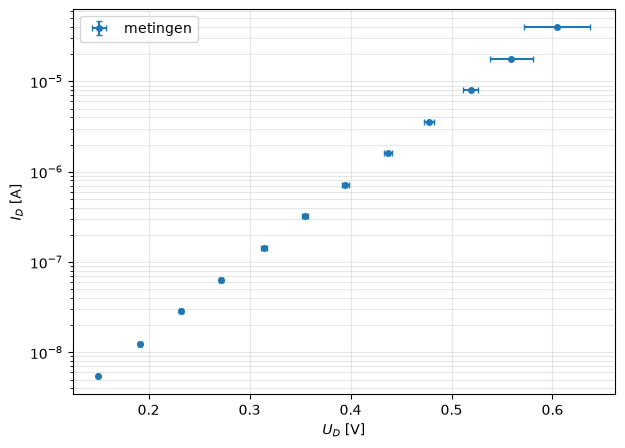

Grootste gat: 0.36 decade tussen U_D = 0.150 en 0.191 V -> meet volgende rond U_D = 0.171 V


In [11]:
#Data processing and analysis: plot (semi-log) en suggestie voor de volgende meting
fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(U_D, I_D, xerr=u_UD, yerr=u_ID, fmt='o', ms=4, capsize=2, label='metingen')
ax.set_yscale('log')
ax.set_xlabel('$U_D$ [V]'); ax.set_ylabel('$I_D$ [A]')
ax.grid(True, which='both', alpha=0.3); ax.legend()
plt.show()

def volgende_meting(U_D, I_D, ondergrens=0.1, bovengrens=0.6):
    '''Zoek het grootste gat in log10(I_D) binnen het meetgebied en geef het midden in U_D.'''
    m = (U_D >= ondergrens) & (U_D <= bovengrens)
    x, y = U_D[m], np.log10(I_D[m])
    o = np.argsort(x); x, y = x[o], y[o]
    if len(x) < 2:
        print('Te weinig punten voor een suggestie.'); return
    k = np.argmax(np.diff(y))
    print(f'Grootste gat: {np.diff(y)[k]:.2f} decade tussen U_D = {x[k]:.3f} en {x[k+1]:.3f} V '
          f'-> meet volgende rond U_D = {(x[k]+x[k+1])/2:.3f} V')

volgende_meting(U_D, I_D)

I0 = 2.984e-10 A,   b = 19.674 ± 0.155 1/V,   chi2_red = 0.04


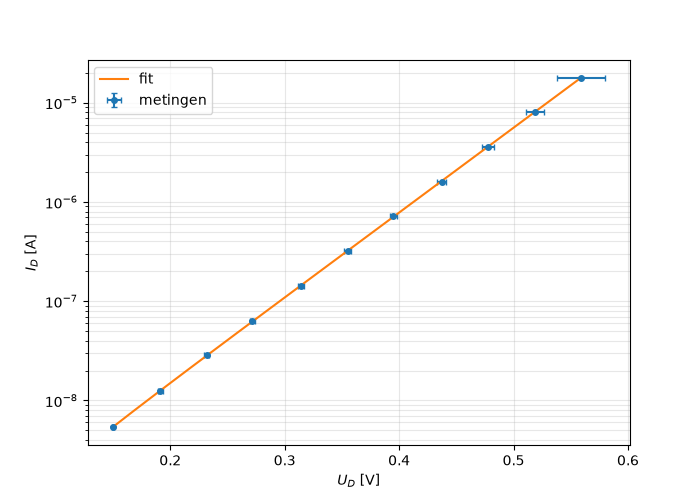

In [15]:
#Data processing and analysis: fit I_D = I0 (exp(b U_D) - 1)
sel = (U_D >= 0.1) & (U_D <= 0.6)
x, y, ux, uy = U_D[sel], I_D[sel], u_UD[sel], u_ID[sel]
assert len(x) >= 3, 'Te weinig meetpunten tussen 0,1 en 0,6 V voor een fit.'

b0, a0 = np.polyfit(x, np.log(y), 1)      # startwaarden uit rechte lijn van ln(I) tegen U_D
p0 = [a0, b0]

sigma = uy.copy()
for _ in range(5):                         # effectieve variantie: u(U_D) omgerekend naar I
    popt, pcov = curve_fit(diode, x, y, p0=p0, sigma=sigma, absolute_sigma=True)
    dIdU = np.exp(popt[0])*popt[1]*np.exp(popt[1]*x)
    sigma = np.sqrt(uy**2 + (dIdU*ux)**2)
    p0 = popt

lnI0, b = popt
u_lnI0, u_b = np.sqrt(np.diag(pcov))
chi2red = np.sum(((y - diode(x, *popt))/sigma)**2)/(len(x) - 2)
print(f'I0 = {np.exp(lnI0):.3e} A,   b = {b:.3f} ± {u_b:.3f} 1/V,   chi2_red = {chi2red:.2f}')

xx = np.linspace(x.min(), x.max(), 300)
fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(x, y, xerr=ux, yerr=uy, fmt='o', ms=4, capsize=2, label='metingen')
ax.plot(xx, diode(xx, *popt), label='fit')
ax.set_yscale('log'); ax.set_xlabel('$U_D$ [V]'); ax.set_ylabel('$I_D$ [A]')
ax.grid(True, which='both', alpha=0.3); ax.legend()
plt.show()

**Describing the pattern in the processed data:**  

In [13]:
#Calculations of e.a. measurement uncertainties, and providing final answers.
kB = -q/(b*n*T)
u_kB = abs(kB)*np.sqrt((u_b/b)**2 + (u_n/n)**2 + (u_T/T)**2)
kB_tabel = 1.380649e-23
print(f'k_B = ({kB:.3e} ± {u_kB:.1e}) J/K')
print(f'tabelwaarde = {kB_tabel:.6e} J/K, verschil = {abs(kB-kB_tabel)/u_kB:.1f} x onzekerheid')
print('bijdragen (relatief): b {:.1%}, n {:.1%}, T {:.1%}'.format(u_b/abs(b), u_n/n, u_T/T))

k_B = (1.389e-23 ± 7.0e-25) J/K
tabelwaarde = 1.380649e-23 J/K, verschil = 0.1 x onzekerheid
bijdragen (relatief): b 0.8%, n 5.0%, T 0.3%


**Notes:**  

# Discussion

# Conclusion

# Additional notes, remarks, explanations, thoughts etc